# Practical Application III: Comparing Classifiers

In this project I compare four classifiers (KNN, Logistic Regression, Decision Tree and SVM) on a dataset from a Portuguese bank's telephone marketing campaigns.

## Business Understanding

The bank calls clients to sell term deposits, but most calls don't lead to a sale. If we can predict which clients are likely to say yes, the bank can call those people first. That saves time and money and annoys fewer customers.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, roc_auc_score, recall_score, precision_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

### Problem 1: Understanding the Data

According to the paper, the data comes from **17 marketing campaigns** run between May 2008 and November 2010.

### Problem 2: Read in the Data

In [2]:
bank = pd.read_csv('data/bank-additional-full.csv', sep=';')
print(bank.shape)
bank.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Problem 3: Understanding the Features

In [3]:
bank.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [4]:
# There are no nulls, but some columns use 'unknown' instead
print('Duplicates:', bank.duplicated().sum())
(bank == 'unknown').sum()[lambda s: s > 0]

Duplicates: 12


job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64

What I found:
- There are no missing values, but six columns contain `unknown`. I keep `unknown` as its own category.
- There are 12 duplicate rows, which I remove.
- `duration` is only known after the call ends, so I drop it. Otherwise the model would be "cheating".
- In `pdays`, the value 999 means the client was never contacted before. I replace `pdays` with a simple yes/no column.
- The target `y` is text (`yes`/`no`), so I convert it to 1/0.

In [5]:
bank = bank.drop_duplicates().drop(columns='duration')
bank['contacted_before'] = (bank['pdays'] != 999).astype(int)
bank = bank.drop(columns='pdays')
bank['y'] = (bank['y'] == 'yes').astype(int)
bank.shape

(41176, 20)

### Exploring the Data

In [6]:
print(f"Share of clients who subscribed: {bank['y'].mean():.1%}")
bank[['age', 'campaign', 'euribor3m', 'contacted_before', 'y']].groupby('y').mean().round(2)

Share of clients who subscribed: 11.3%


,age,campaign,euribor3m,contacted_before
y,,,,
0,39.91,2.63,3.81,0.01
1,40.91,2.05,2.12,0.21


Only about **11%** of clients said yes, so the classes are very unbalanced.

Compared with non-subscribers, subscribers:
- were called fewer times in this campaign (2.1 vs 2.6 calls on average);
- were much more often contacted in an earlier campaign;
- were contacted when the interest rate (`euribor3m`) was lower.

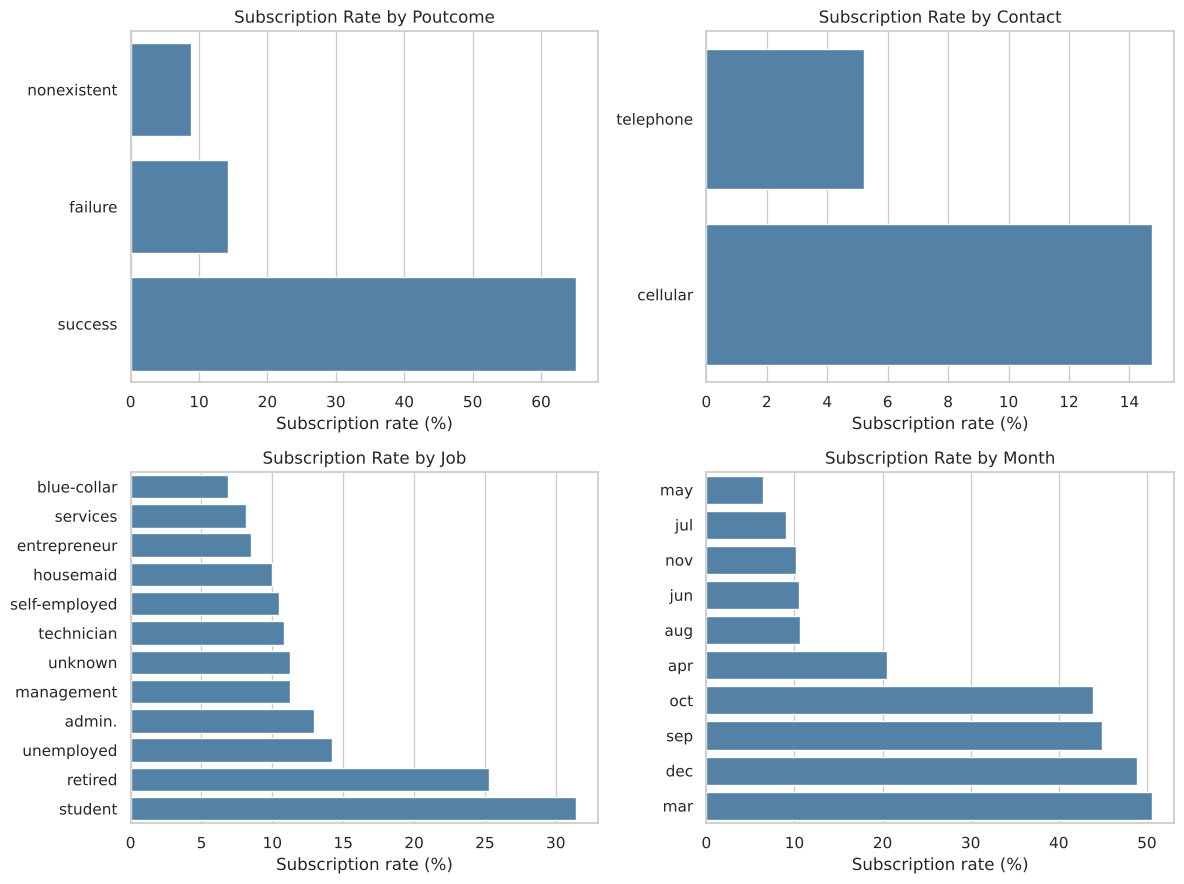

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.ravel(), ['poutcome', 'contact', 'job', 'month']):
    rate = bank.groupby(col)['y'].mean().sort_values() * 100
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color='steelblue')
    ax.set_title(f'Subscription Rate by {col.title()}')
    ax.set_xlabel('Subscription rate (%)')
    ax.set_ylabel('')
plt.tight_layout()
plt.savefig('images/subscription_rates.png')
plt.show()

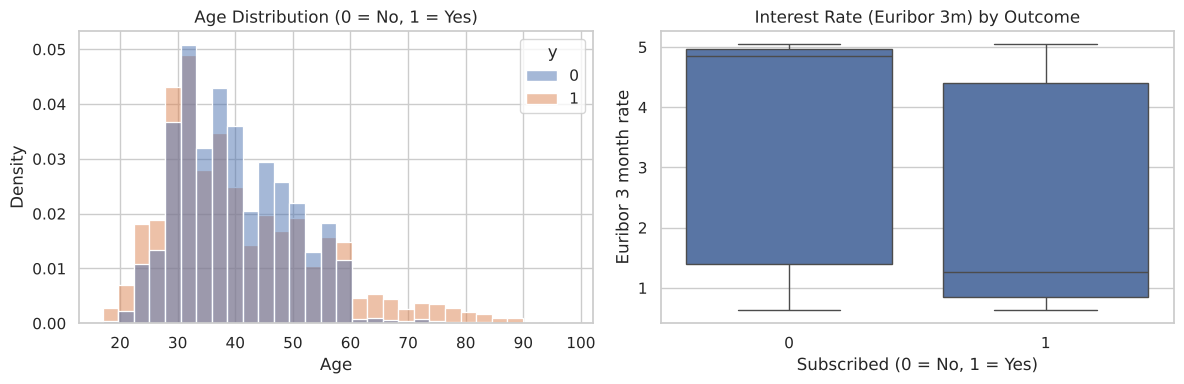

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=bank, x='age', hue='y', stat='density', common_norm=False, bins=30, ax=axes[0])
axes[0].set_title('Age Distribution (0 = No, 1 = Yes)')
axes[0].set_xlabel('Age')
sns.boxplot(data=bank, x='y', y='euribor3m', ax=axes[1])
axes[1].set_title('Interest Rate (Euribor 3m) by Outcome')
axes[1].set_xlabel('Subscribed (0 = No, 1 = Yes)')
axes[1].set_ylabel('Euribor 3 month rate')
plt.tight_layout()
plt.savefig('images/age_and_rate.png')
plt.show()

From the charts:
- Clients who said yes in a **previous campaign** subscribe about 65% of the time.
- **Cell phone** calls work better than landline calls (15% vs 5%).
- **Students and retirees** subscribe the most.
- **May** has the most calls but the lowest success rate. March, September, October and December do much better.
- Younger and older clients (60+) subscribe more than middle-aged ones.
- Most subscriptions happened when interest rates were low.

#### Are these differences significant?

I used a chi-square test to check whether each categorical feature is related to the outcome.

In [9]:
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan',
            'contact', 'month', 'day_of_week', 'poutcome']
p_values = {col: chi2_contingency(pd.crosstab(bank[col], bank['y']))[1] for col in cat_cols}
pd.Series(p_values, name='p_value').sort_values().map('{:.3g}'.format)

month                  0
poutcome               0
job            3.27e-199
contact        1.72e-189
default         5.22e-89
education       3.75e-38
marital         1.78e-26
day_of_week     3.09e-05
housing           0.0566
loan               0.577
Name: p_value, dtype: str

All features have p < 0.05 except **housing** and **loan**. This means having a housing or personal loan doesn't really affect whether someone subscribes. All other features are significantly related to the outcome.

### Problem 4: Business Objective

Predict whether a client will subscribe to a term deposit using only information known **before** the call. The bank can then rank clients and call the most promising ones first.

### Problem 5: Engineering Features

To start, I use only the bank client features. I scale `age` and one-hot encode the categorical columns.

In [10]:
client_cols = ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan']
X = bank[client_cols]
y = bank['y']

preprocess = ColumnTransformer([
    ('num', StandardScaler(), ['age']),
    ('cat', OneHotEncoder(handle_unknown='ignore'), client_cols[1:])
])

### Problem 6: Train/Test Split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
X_train.shape, X_test.shape

((28823, 7), (12353, 7))

### Problem 7: A Baseline Model

In [12]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print('Baseline accuracy:', round(accuracy_score(y_test, baseline.predict(X_test)), 4))

Baseline accuracy: 0.8873


If we always guess "no", we are right **88.7%** of the time. Any useful model must do better than that.

### Problem 8: A Simple Model

In [13]:
lr = Pipeline([('prep', preprocess), ('model', LogisticRegression(max_iter=1000))])
lr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['age','job','marital',...,'default','housing','loan']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere 

### Problem 9: Score the Model

In [14]:
print('Test accuracy:', round(lr.score(X_test, y_test), 4))
print('Test ROC-AUC:', round(roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1]), 4))

Test accuracy: 0.8873
Test ROC-AUC: 0.6501


The accuracy is **88.7%**, exactly the same as the baseline. The model just predicts "no" for everyone. This shows that accuracy is not a good metric for this problem.

### Problem 10: Model Comparisons

In [15]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': SVC(),
}

results = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    start = time.time()
    pipe.fit(X_train, y_train)
    results.append([name, round(time.time() - start, 2),
                    round(pipe.score(X_train, y_train), 4), round(pipe.score(X_test, y_test), 4)])

results_df = pd.DataFrame(results, columns=['Model', 'Train Time', 'Train Accuracy', 'Test Accuracy'])
results_df

,Model,Train Time,Train Accuracy,Test Accuracy
0,Logistic Regression,0.08,0.8873,0.8873
1,KNN,0.03,0.8917,0.8791
2,Decision Tree,0.58,0.9189,0.8630
3,SVM,43.72,0.8882,0.8873


None of the models really beat the baseline:
- The Decision Tree does well on the training data but worse on the test data, so it is **overfitting**.
- SVM takes far longer to train than the other models.

### Problem 11: Improving the Model

What I changed:
1. **More features.** I added contact, campaign history and economic features. I left out `duration`, and also `emp.var.rate` and `nr.employed` because they are almost the same as `euribor3m`.
2. **A better metric.** I use **ROC-AUC** instead of accuracy. Since 89% of answers are "no", accuracy looks good even when the model is useless. ROC-AUC measures how well the model ranks the "yes" clients above the "no" clients, and that ranking is how the bank would use it.
3. **Grid search with 5-fold cross-validation** to tune each model's hyperparameters. SVM is very slow, so I tuned it on a sample of 5,000 rows.

In [16]:
num_cols = ['age', 'campaign', 'previous', 'contacted_before', 'cons.price.idx', 'cons.conf.idx', 'euribor3m']
X = bank[num_cols + cat_cols]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

params = {
    'Logistic Regression': (LogisticRegression(max_iter=1000), {'model__C': [0.01, 0.1, 1, 10]}),
    'KNN': (KNeighborsClassifier(), {'model__n_neighbors': [25, 75, 125]}),
    'Decision Tree': (DecisionTreeClassifier(random_state=42), {'model__max_depth': [3, 5, 7, 10],
                                                                'model__min_samples_leaf': [20, 50]}),
    'SVM': (SVC(), {'model__C': [0.1, 1], 'model__kernel': ['linear', 'rbf']}),
}

tuned = []
best_models = {}
for name, (model, grid) in params.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    search = GridSearchCV(pipe, grid, scoring='roc_auc', cv=5, n_jobs=-1)
    # SVM is slow, so it is trained on a 5,000 row sample
    X_fit, y_fit = (X_train.sample(5000, random_state=42), y_train.sample(5000, random_state=42)) \
                   if name == 'SVM' else (X_train, y_train)
    start = time.time()
    search.fit(X_fit, y_fit)
    best_models[name] = search.best_estimator_
    # SVM has no predict_proba by default, so use its decision function instead
    if hasattr(search, 'predict_proba'):
        test_scores = search.predict_proba(X_test)[:, 1]
    else:
        test_scores = search.decision_function(X_test)
    tuned.append([name, round(time.time() - start, 1), search.best_params_,
                  round(search.best_score_, 3), round(roc_auc_score(y_test, test_scores), 3)])

tuned_df = pd.DataFrame(tuned, columns=['Model', 'Search Time', 'Best Params', 'CV ROC-AUC', 'Test ROC-AUC'])
tuned_df

,Model,Search Time,Best Params,CV ROC-AUC,Test ROC-AUC
0,Logistic Regression,2.3,{'model__C': 0.1},0.784,0.800
1,KNN,20.8,{'model__n_neighbors': 125},0.778,0.797
2,Decision Tree,2.4,"{'model__max_depth': 7, 'model__min_samples_le...",0.791,0.801
3,SVM,5.6,"{'model__C': 1, 'model__kernel': 'rbf'}",0.718,0.712


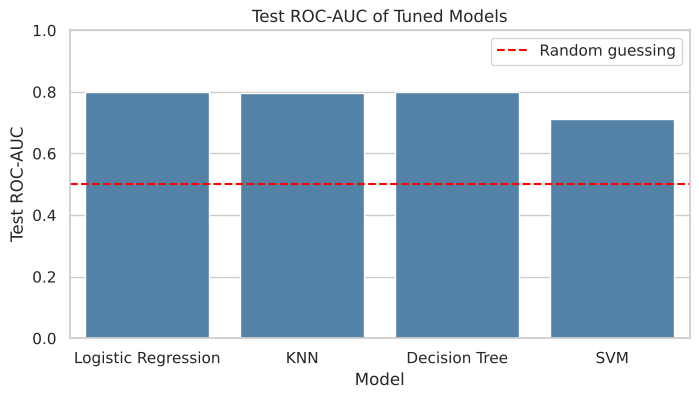

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=tuned_df, x='Model', y='Test ROC-AUC', color='steelblue', ax=ax)
ax.axhline(0.5, color='red', linestyle='--', label='Random guessing')
ax.set_title('Test ROC-AUC of Tuned Models')
ax.set_ylim(0, 1)
ax.legend()
plt.savefig('images/model_comparison.png')
plt.show()

#### What does this mean for the bank?

If the bank only calls the 20% of clients with the highest predicted scores, how many of the real subscribers does it reach?

In [18]:
scores = best_models['Logistic Regression'].predict_proba(X_test)[:, 1]
top_20 = (scores >= np.quantile(scores, 0.8)).astype(int)
print(f'Subscribers reached: {recall_score(y_test, top_20):.0%}')
print(f'Success rate of these calls: {precision_score(y_test, top_20):.0%}  (vs {y_test.mean():.0%} if calling at random)')

Subscribers reached: 64%
Success rate of these calls: 36%  (vs 11% if calling at random)


#### Logistic Regression coefficients

The numeric features are scaled, so their odds ratios show the effect of a one standard deviation increase. An odds ratio above 1 means more likely to subscribe; below 1 means less likely. Categories with very few rows (like `default = yes`, which has only 3 rows, or `marital = unknown`) are left out because their coefficients aren't reliable.

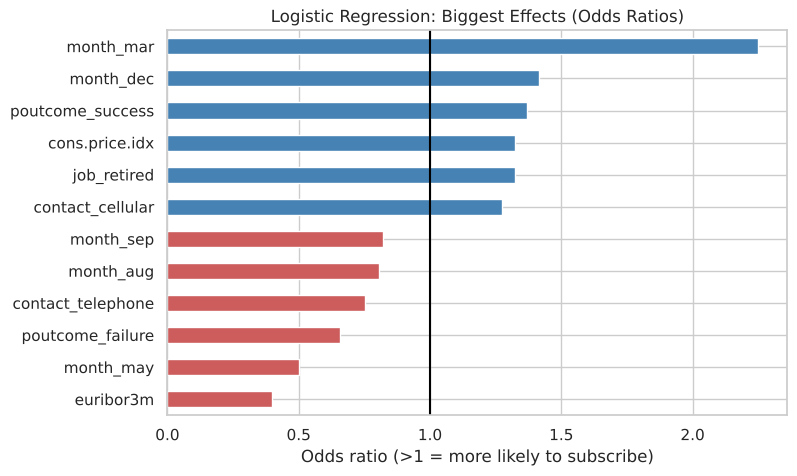

In [19]:
best_lr = best_models['Logistic Regression']
names = best_lr.named_steps['prep'].get_feature_names_out()
odds = pd.Series(np.exp(best_lr.named_steps['model'].coef_[0]),
                 index=[n.split('__')[1] for n in names])
odds = odds.drop(['default_yes', 'default_no', 'default_unknown', 'education_illiterate', 'marital_unknown'])
top = pd.concat([odds.nlargest(6), odds.nsmallest(6)]).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
top.plot(kind='barh', ax=ax, color=['indianred' if v < 1 else 'steelblue' for v in top])
ax.axvline(1, color='black')
ax.set_title('Logistic Regression: Biggest Effects (Odds Ratios)')
ax.set_xlabel('Odds ratio (>1 = more likely to subscribe)')
plt.savefig('images/odds_ratios.png', bbox_inches='tight')
plt.show()

Reading the coefficients:
- **euribor3m** has the strongest effect. When interest rates go up, clients are much less likely to subscribe.
- Calling in **March or December** increases the chances. **May**, August and September lower them.
- A **previous success** increases the chances.
- **Landline** calls lower the chances compared to cell phone calls.
- **Retired** clients are more likely to subscribe.

## Findings

- **Best models:** after adding features and tuning, **Logistic Regression and the Decision Tree did best**, with a test ROC-AUC of about **0.80** (random guessing is 0.5). KNN was close behind. SVM was the slowest and did worse.
- **Recommendation:** I recommend **Logistic Regression**. It is fast, it performs as well as the others, and its results are easy to explain.
- **Targeting:** if the bank calls only the top 20% of clients the model picks, it reaches about **64% of all subscribers**, with a success rate about 3 times higher than calling at random.

### Actionable insights for the bank
1. **Use the model to rank clients** and call the most likely subscribers first.
2. **Call past "yes" clients first.** About 65% of them subscribe again.
3. **Call cell phones** rather than landlines.
4. **Don't call the same person too many times.** Success drops after 2–3 calls.
5. **Plan campaigns around timing.** Avoid relying on May; March, September, October and December work much better, as do periods of low interest rates.
6. **Target students and retirees,** who subscribe the most.

### Next steps
- Try other models such as Random Forest or Gradient Boosting.
- Choose the number of clients to call based on the real cost of a call and the value of a deposit.
- Test the model on a real campaign (model-ranked list vs the normal list).
- Add more recent data, because this dataset ends in 2010.